# Dataset #5: NBA Salary Cap & Contracts, 2015-16 to 2026-27 (Mr-Bridge, Hugging Face)

**Source and access.** [Mr-Bridge/nba-salary-cap-contracts-2016-2026](https://huggingface.co/datasets/Mr-Bridge/nba-salary-cap-contracts-2016-2026) is a free, public dataset of 15 CSV tables. Player salaries come from HoopsHype's public salary data (snapshot accessed 2026-07-07). League cap rules come from the 2017 and 2023 NBA/NBPA collective bargaining agreements and NBA cap releases, cross-checked against Basketball-Reference and Spotrac. We use four of the tables, downloaded by `00-Download-Raw-Data.ipynb` into `data-files/00-raw/`:
- `player_salaries.csv` (7,288 rows): one row per player, per team, per season. This is the core table.
- `cap_tax_aprons.csv` (12 rows): the league's salary cap, luxury-tax line, and first/second apron for each season.
- `min_salaries.csv` (12 rows): the rookie and 10-year-veteran minimum salary for each season.
- `team_payrolls.csv` (360 rows): total payroll per team-season. We only use it to verify our own payroll totals.

**Important metrics.**
- `salary`: a player's salary (cap hit) with a team for a season, in **US dollars (nominal, not inflation-adjusted)**. Values range from about \$5K (a few days on a 10-day contract) to about \$60M (supermax stars). The median is about \$2.7M, and the distribution is very right-skewed.
- `salary_cap`: the soft cap on team payroll for a season, in USD. It grew from \$70.0M in 2015-16 to \$154.6M in 2025-26 (the jump in 2016 came from a new TV deal). Because the cap more than doubled, **raw dollars aren't comparable across seasons**, so we convert salaries to **% of that season's cap**. A max contract *starts* at 25%, 30%, or 35% of the cap depending on years of service. Raises of up to 8% a year can push its later years to about 40% (e.g. Stephen Curry in 2021-22, after the COVID cap freeze), but nothing should come close to 45%.
- `luxury_tax_line`, `first_apron`, `second_apron` (USD): payroll thresholds above the cap. A team over the tax line pays a penalty tax on every dollar over. Since the 2023 CBA, teams over the first apron, and even more so the second apron, lose key trade tools (for example, they can't take back more salary than they send out, or combine salaries in trades). Before 2023-24 there was no second apron (it is blank), and `first_apron` holds the older "tax apron" (hard-cap line). We use these to place every team-season in a **cap tier**: under cap → over cap → over tax → over 1st apron → over 2nd apron. We expect teams in higher tiers to be under more pressure to trade salary away.
- `rookie_minimum` / `ten_year_veteran_minimum` (USD): the smallest full-season salary a player can earn. A salary below the rookie minimum means the player was not on a standard full-season contract (a 10-day deal, a two-way deal, a prorated signing, or being waived).
- `two_way`: True if the player was on a two-way contract (split between the NBA team and its G League affiliate, paid much less than a standard contract).
- Derived: `pct_of_team_payroll` (the player's share of their team's payroll) and `changed_team_next_season` (whether the player's main team changed in the following season, which can come from a trade *or* free agency).

**Concerns.**
1. *Snapshot, not final accounting.* The card warns that these are contract and cap-hit snapshots, which can differ from final figures (incentives, dead money, cap holds, converted contracts). The 2026-27 season is a forward-looking snapshot: only 483 rows, because many players hadn't signed yet. We exclude it from the cleaned tables.
2. *Contract details are mostly empty.* `player_option`, `qualifying_offer`, and `terminated` are False in every row, `team_option` is True in only 12 rows (all 2026-27), and `notes` is always blank. The dataset has no contract length or years remaining. That was one of the variables we wanted most for our hypothesis, so we will need another source for it (e.g. Spotrac or Basketball-Reference contract pages).
3. *Missing IDs are not missing at random.* 157 rows (2%) have no `player_id`. They are mostly fringe or low-salary players and rows where HoopsHype used a legal name instead of a common name (e.g. "Louis Williams" = Lou Williams, "Patrick Mills" = Patty Mills). Because of this we key players by a normalized name instead of the ID. Name variants could still split one player into two keys.
4. *Inconsistent `team_id`.* IDs are 1–29 for 29 teams, but Charlotte's is 5312. We drop `team_id` and identify teams by name.
5. *Multiple rows per player-season.* 439 player-seasons have salary with more than one team (traded or waived mid-season). Five player-seasons have two rows *with the same team* (e.g. a two-way deal converted to a standard one, or a waived contract plus a new one). These are real but need to be combined before we have one row per player-season.
6. *Possibly incomplete seasons.* 2019-20 has fewer rows (518) and smaller average rosters (~17 players per team vs. ~21 in other seasons), and no team is above the tax line that season. This suggests missing salary rows (COVID-era roster churn may not have been captured). We will cross-check 2019-20 payrolls against Basketball-Reference before relying on them.
7. *Source bias.* Salary data compiled by HoopsHype (a media site) may be most accurate for high-profile players and less careful for end-of-bench or 10-day players.

## Setup

All file paths come from `nba_cleaning_utils.py`, which points at the `data-files/` folder (`RAW` = `00-raw/`, `INTERIM` = `01-interim/`, `PROCESSED` = `02-processed/`).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# normalize_name() builds the player name key. It lives in nba_cleaning_utils.py because
# Dataset #6 must build exactly the same key to join on it.
from nba_cleaning_utils import RAW, INTERIM, PROCESSED, normalize_name

## 5A. Load the dataset

In [2]:
## 5A. LOAD the dataset (raw CSVs downloaded into data-files/00-raw/ by 00-Download-Raw-Data)
salaries_raw      = pd.read_csv(RAW / 'hf_player_salaries.csv')
cap_raw           = pd.read_csv(RAW / 'hf_cap_tax_aprons.csv')
min_raw           = pd.read_csv(RAW / 'hf_min_salaries.csv')
team_payrolls_raw = pd.read_csv(RAW / 'hf_team_payrolls.csv')


display(salaries_raw.head())
display(cap_raw.head(3))

,season_year,season,player_id,player,salary,team_id,team,team_option,player_option,qualifying_offer,two_way,terminated,notes,source
0,2015,2015-16,3100.0,Kobe Bryant,25000000,13,Los Angeles Lakers,False,False,False,False,False,NaN,"HoopsHype salaries GraphQL endpoint, accessed ..."
1,2015,2015-16,214152.0,LeBron James,22970500,5,Cleveland Cavaliers,False,False,False,False,False,NaN,"HoopsHype salaries GraphQL endpoint, accessed ..."
2,2015,2015-16,172890.0,Carmelo Anthony,22875000,18,New York Knicks,False,False,False,False,False,NaN,"HoopsHype salaries GraphQL endpoint, accessed ..."
3,2015,2015-16,253975.0,Dwight Howard,22359364,10,Houston Rockets,False,False,False,False,False,NaN,"HoopsHype salaries GraphQL endpoint, accessed ..."
4,2015,2015-16,172631.0,Chris Bosh,22192730,14,Miami Heat,False,False,False,False,False,NaN,"HoopsHype salaries GraphQL endpoint, accessed ..."


,season_year,season,salary_cap,luxury_tax_line,first_apron,second_apron,source_status,notes
0,2015,2015-16,70000000,84740000,88740000,NaN,official/cross-check,Pre-spike baseline; old tax apron used as firs...
1,2016,2016-17,94143000,113287000,117287000,NaN,official/cross-check,2016 cap spike after national TV deal; old tax...
2,2017,2017-18,99093000,119266000,125266000,NaN,official/cross-check,2017 CBA season; tax apron/hard-cap line.


## 5B. Tidy the dataset (or show it is already tidy)

In [3]:
## 5B. TIDY -- demonstrate the data is already tidy
# player_salaries: each row is one observation (one player's salary with one team in one season) and
# each column is one variable. The cap and minimum tables have one row per season. So all four tables
# are already tidy and need no reshaping (no melting/pivoting).
# The one thing to check is how often the natural keys repeat, because we will later build a
# one-row-per-player-season table:
multi_team = salaries_raw.groupby(['season', 'player'])['team'].nunique()
same_team_dupes = salaries_raw[salaries_raw.duplicated(['season', 'player', 'team'], keep=False)]

print('Exact duplicate rows:', salaries_raw.duplicated().sum())
print('Seasons appearing more than once in the cap table:', cap_raw['season'].duplicated().sum())
print('Player-seasons with salary from >1 team (traded/waived mid-season):', (multi_team > 1).sum())
print('Rows sharing the same (season, player, team):', len(same_team_dupes))
display(same_team_dupes[['season', 'player', 'team', 'salary', 'two_way']].sort_values(['season', 'player']))
# These repeats are legitimate (two contracts, or salary paid by two teams), not tidiness violations.
# They are combined in 5F.

Exact duplicate rows: 0
Seasons appearing more than once in the cap table: 0
Player-seasons with salary from >1 team (traded/waived mid-season): 439
Rows sharing the same (season, player, team): 10


,season,player,team,salary,two_way
1688,2017-18,Milton Doyle,Brooklyn Nets,77250,False
1748,2017-18,Milton Doyle,Brooklyn Nets,50000,False
4265,2022-23,John Wall,Houston Rockets,40866760,False
4450,2022-23,John Wall,Houston Rockets,6479000,False
4823,2022-23,Jordan Hall,San Antonio Spurs,175479,False
4878,2022-23,Jordan Hall,San Antonio Spurs,17548,False
4806,2022-23,Orlando Robinson,Miami Heat,350959,True
4873,2022-23,Orlando Robinson,Miami Heat,35096,False
6619,2025-26,James Wiseman,Indiana Pacers,1000000,False
6752,2025-26,James Wiseman,Indiana Pacers,153330,False


## 5C. Size of the dataset

In [4]:
## 5C. SIZE of the dataset
print('player_salaries:', salaries_raw.shape, '| cap_tax_aprons:', cap_raw.shape,
      '| min_salaries:', min_raw.shape, '| team_payrolls:', team_payrolls_raw.shape)
print(f"{salaries_raw['season'].nunique()} seasons ({salaries_raw['season'].min()} to {salaries_raw['season'].max()}), "
      f"{salaries_raw['player'].nunique()} distinct players, {salaries_raw['team'].nunique()} teams")

# Rows per season and average roster size: 2026-27 is clearly incomplete (forward-looking snapshot),
# and 2019-20 looks thin.
size_by_season = pd.DataFrame({
    'rows': salaries_raw.groupby('season').size(),
    'avg_players_per_team': salaries_raw.groupby(['season', 'team'])['player'].nunique()
                                        .groupby('season').mean().round(1)})
display(size_by_season.T)

player_salaries: (7288, 14) | cap_tax_aprons: (12, 8) | min_salaries: (12, 5) | team_payrolls: (360, 7)
12 seasons (2015-16 to 2026-27), 1681 distinct players, 30 teams


season,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
rows,538.0,590.0,631.0,621.0,518.0,618.0,740.0,629.0,663.0,617.0,640.0,483.0
avg_players_per_team,17.9,19.7,21.0,20.7,17.3,20.6,24.7,20.9,22.1,20.6,21.3,16.1


## 5D. Missing data: how much, where, and is it random?

,season_year,season,player_id,player,salary,team_id,team,team_option,player_option,qualifying_offer,two_way,terminated,notes,source
n_missing,0.0,0.0,157.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7288.0,0.0
pct_missing,0.0,0.0,2.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0


,team_option,player_option,qualifying_offer,two_way,terminated
n_true,12,0,0,671,0


team_option=True only appears in: <StringArray>
['2026-27']
Length: 1, dtype: str
Distinct values of `source`: 1
Seasons with no second_apron: ['2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']


,rows,median_salary,share_two_way,share_below_1M
player_id_missing,,,,
False,7131,2770560.0,0.09,0.27
True,157,678882.0,0.13,0.57


Missing-id rows whose exact name has an id elsewhere: 0 of 157
Examples: ['Enes Kanter', 'Louis Williams', 'Jose Juan Barea', 'Patrick Mills', 'Maurice Williams', 'Ishmael Smith', 'Joseph Young', 'Walter Tavares', 'Christapher Johnson', 'Maurice Ndour', 'Scottie Wilbekin', 'Jonathan Holmes']


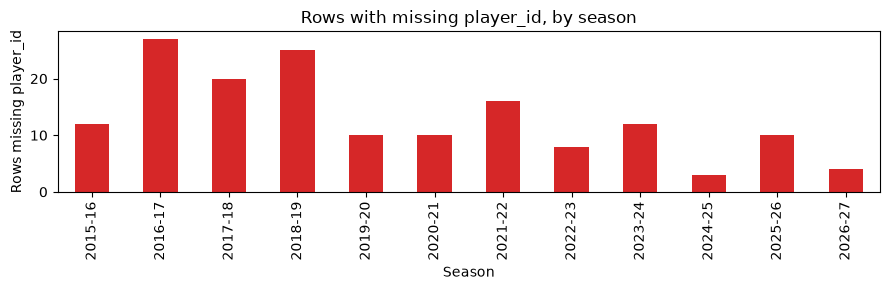

In [5]:
## 5D. MISSINGNESS -- how much, where, and is it random?
display(salaries_raw.isna().sum().rename('n_missing').to_frame()
        .assign(pct_missing=lambda d: (100 * d['n_missing'] / len(salaries_raw)).round(1)).T)

# "Hidden" missingness: boolean contract flags that are never filled in
flag_cols = ['team_option', 'player_option', 'qualifying_offer', 'two_way', 'terminated']
display(salaries_raw[flag_cols].sum().rename('n_true').to_frame().T)
print('team_option=True only appears in:', salaries_raw.loc[salaries_raw['team_option'], 'season'].unique())
print('Distinct values of `source`:', salaries_raw['source'].nunique())
# Pre-2023 seasons have no second apron (the rule did not exist yet): structural, not an error
print('Seasons with no second_apron:', cap_raw.loc[cap_raw['second_apron'].isna(), 'season'].tolist())

# Is the missingness in player_id random? Compare rows with and without an id.
na_id = salaries_raw['player_id'].isna()
display(salaries_raw.groupby(na_id.rename('player_id_missing'))
        .agg(rows=('salary', 'size'), median_salary=('salary', 'median'),
             share_two_way=('two_way', 'mean'),
             share_below_1M=('salary', lambda s: (s < 1_000_000).mean())).round(2))
ids_by_name = salaries_raw.dropna(subset=['player_id']).groupby('player')['player_id'].first()
print('Missing-id rows whose exact name has an id elsewhere:',
      salaries_raw.loc[na_id, 'player'].isin(ids_by_name.index).sum(), 'of', na_id.sum())
print('Examples:', salaries_raw.loc[na_id, 'player'].drop_duplicates().head(12).tolist())
# -> NOT missing at random: missing ids are concentrated among low-salary players and legal-name
#    variants ("Louis Williams" = Lou Williams), so dropping them would bias payroll totals.

fig, ax = plt.subplots(figsize=(9, 3))
salaries_raw.groupby('season')['player_id'].apply(lambda s: s.isna().sum()).plot.bar(ax=ax, color='tab:red')
ax.set_title('Rows with missing player_id, by season')
ax.set_xlabel('Season'); ax.set_ylabel('Rows missing player_id')
plt.tight_layout(); plt.show()

## 5E. Outliers and suspicious entries

,flag_below_rookie_min,flag_above_35pct_cap,flag_impossible_pct_cap,flag_iqr_log_outlier
n_flagged,1790,40,0,33


two_way,False,True,All
flag_below_rookie_min,,,
False,5498,0,5498
True,1119,671,1790
All,6617,671,7288


Smallest salaries:


,season,player,team,salary,two_way
4255,2021-22,Mac McClung,Los Angeles Lakers,5318,False
4882,2022-23,Chance Comanche,Portland Trail Blazers,5849,False
4883,2022-23,RaiQuan Gray,Brooklyn Nets,5849,False
4884,2022-23,Jacob Gilyard,Memphis Grizzlies,5849,True
1127,2016-17,Walter Tavares,Cleveland Cavaliers,6000,False


Largest salaries as % of cap (later years of max deals; should stay well below 45%):


,season,player,team,salary,pct_of_cap
3516,2021-22,Stephen Curry,Golden State Warriors,45780966,40.7
5548,2024-25,Stephen Curry,Golden State Warriors,55761217,39.7
3517,2021-22,James Harden,Philadelphia 76ers,44310840,39.4
3518,2021-22,John Wall,Houston Rockets,44310840,39.4
2898,2020-21,Stephen Curry,Golden State Warriors,43006362,39.4


Non-standard team_id: {'Charlotte Hornets': 5312}


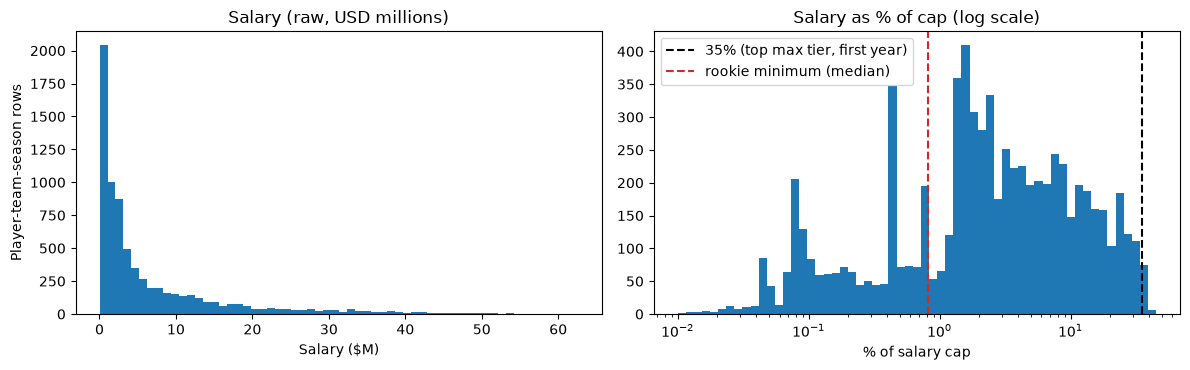

In [6]:
## 5E. OUTLIERS / SUSPICIOUS ENTRIES
# Raw dollars are not comparable across seasons (the cap went from $70M to $155M), so we judge salaries
# relative to that season's salary cap and minimum salary.
sal = (salaries_raw
       .merge(cap_raw[['season', 'salary_cap']], on='season', how='left')
       .merge(min_raw[['season', 'rookie_minimum']], on='season', how='left'))
sal['pct_of_cap'] = 100 * sal['salary'] / sal['salary_cap']

sal['flag_below_rookie_min'] = sal['salary'] < sal['rookie_minimum']   # partial / prorated / 10-day / two-way
# A max contract starts at <=35% of the cap, but annual raises (up to 8%) plus slow cap growth (e.g. the
# COVID freeze) can push later years above 35%. Above ~45% would be impossible, so that is our error check.
sal['flag_above_35pct_cap'] = sal['pct_of_cap'] > 35
sal['flag_impossible_pct_cap'] = sal['pct_of_cap'] > 45
log_sal = np.log10(sal['salary'])
q1, q3 = log_sal.quantile([.25, .75])
sal['flag_iqr_log_outlier'] = ~log_sal.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))

display(sal[['flag_below_rookie_min', 'flag_above_35pct_cap', 'flag_impossible_pct_cap', 'flag_iqr_log_outlier']].sum().rename('n_flagged').to_frame().T)
display(pd.crosstab(sal['flag_below_rookie_min'], sal['two_way'], margins=True))
print('Smallest salaries:')
display(sal.nsmallest(5, 'salary')[['season', 'player', 'team', 'salary', 'two_way']])
print('Largest salaries as % of cap (later years of max deals; should stay well below 45%):')
display(sal.nlargest(5, 'pct_of_cap')[['season', 'player', 'team', 'salary', 'pct_of_cap']].round(1))

# Suspicious ids: team_id should be 1-30, but Charlotte's is 5312
team_ids = salaries_raw.groupby('team')['team_id'].first()
print('Non-standard team_id:', team_ids[team_ids > 30].to_dict())

# Visual check of the salary distribution, relative to the cap
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(sal['salary'] / 1e6, bins=60, color='tab:blue')
axes[0].set_title('Salary (raw, USD millions)')
axes[0].set_xlabel('Salary ($M)'); axes[0].set_ylabel('Player-team-season rows')
axes[1].hist(sal['pct_of_cap'], bins=np.logspace(-2, np.log10(45), 60), color='tab:blue')
axes[1].set_xscale('log')
axes[1].axvline(35, color='k', ls='--', label='35% (top max tier, first year)')
axes[1].axvline((sal['rookie_minimum'] / sal['salary_cap']).median() * 100, color='tab:red', ls='--',
                label='rookie minimum (median)')
axes[1].set_title('Salary as % of cap (log scale)')
axes[1].set_xlabel('% of salary cap'); axes[1].legend()
plt.tight_layout(); plt.show()

## 5F. Clean the data (and justify missing-data handling)

In [7]:
## 5F. CLEAN + build tidy analysis tables
# Cleaning decisions (and why):
#  1. Drop the 2026-27 season. It is an incomplete forward-looking snapshot (483 rows vs ~600-700),
#     and its offseason (summer 2027) has not happened yet.
#  2. Drop columns that carry no information: notes (100% missing), source (one constant value),
#     player_option / qualifying_offer / terminated (always False), team_option (only set in 2026-27),
#     and team_id (inconsistent; team name is a cleaner key).
#  3. Keep rows with a missing player_id (no dropna). These are real salaries that count toward team
#     payroll, and the missingness is concentrated among low-salary players and name variants, so dropping
#     them would bias payroll and roster numbers. Instead every player gets a normalized-name key
#     (`name_key`), which is also how we will match players to the transactions data (Dataset #6).
#  4. Keep low/partial salaries (below the rookie minimum) but flag them. They are real (10-day deals,
#     waived players, two-way contracts) and matter for payroll, but a model may want to exclude them.
#  5. Combine the 5 (season, player, team) pairs with two rows into one row by summing salary.
#     They are two contracts with the same team in the same season.
salaries = (salaries_raw[salaries_raw['season_year'] <= 2025]
            .drop(columns=['notes', 'source', 'team_option', 'player_option', 'qualifying_offer',
                           'terminated', 'team_id'])
            .assign(name_key=lambda d: d['player'].map(normalize_name)))

# Sanity check: does the name key ever merge two *different* player ids in one season?
collisions = (salaries.dropna(subset=['player_id'])
              .groupby(['season', 'name_key'])['player_id'].nunique())
print('Name-key collisions within a season (different ids, same key):', (collisions > 1).sum())

contracts = (salaries
             .groupby(['season_year', 'season', 'name_key', 'team'], as_index=False)
             .agg(player=('player', 'first'), player_id=('player_id', 'first'),
                  salary=('salary', 'sum'), two_way=('two_way', 'any'),
                  n_contract_rows=('salary', 'size')))

# Team-season table: payroll and cap tier
team_season = (contracts.groupby(['season_year', 'season', 'team'], as_index=False)
               .agg(payroll=('salary', 'sum'), n_players=('name_key', 'nunique'),
                    n_two_way=('two_way', 'sum'))
               .merge(cap_raw[['season', 'salary_cap', 'luxury_tax_line', 'first_apron', 'second_apron']],
                      on='season', how='left'))
team_season['payroll_pct_cap'] = (100 * team_season['payroll'] / team_season['salary_cap']).round(1)
team_season['cap_tier'] = np.select(
    [team_season['second_apron'].notna() & (team_season['payroll'] >= team_season['second_apron']),
     team_season['payroll'] >= team_season['first_apron'],
     team_season['payroll'] >= team_season['luxury_tax_line'],
     team_season['payroll'] >= team_season['salary_cap']],
    ['over_2nd_apron', 'over_1st_apron', 'over_tax', 'over_cap'], default='under_cap')

# Check our payroll totals against the dataset's own team_payrolls table
chk = team_season.merge(team_payrolls_raw[['season', 'team', 'payroll']], on=['season', 'team'],
                        suffixes=('', '_hf'))
print(f"Team payrolls matching team_payrolls.csv: {(chk['payroll'] == chk['payroll_hf']).mean():.0%} "
      f"of {len(chk)} team-seasons")

# Player-season table: one row per player per season. The primary team is the team that paid the most.
contracts = contracts.merge(team_season[['season', 'team', 'payroll']], on=['season', 'team'], how='left')
contracts['pct_of_team_payroll'] = 100 * contracts['salary'] / contracts['payroll']
player_season = (contracts.sort_values('salary', ascending=False)
                 .groupby(['season_year', 'season', 'name_key'], as_index=False)
                 .agg(player=('player', 'first'), player_id=('player_id', 'first'),
                      primary_team=('team', 'first'), total_salary=('salary', 'sum'),
                      pct_of_team_payroll=('pct_of_team_payroll', 'first'),
                      n_teams=('team', 'nunique'), two_way=('two_way', 'any'))
                 .merge(cap_raw[['season', 'salary_cap']], on='season', how='left')
                 .merge(min_raw[['season', 'rookie_minimum']], on='season', how='left'))
player_season['salary_pct_cap'] = 100 * player_season['total_salary'] / player_season['salary_cap']
player_season['flag_below_rookie_min'] = player_season['total_salary'] < player_season['rookie_minimum']
player_season = player_season.drop(columns=['salary_cap', 'rookie_minimum'])

# Next season's primary team. NaN if the player has no salary next season (left the league / unsigned)
# or if this is 2025-26 (we dropped 2026-27).
nxt = (player_season[['season_year', 'name_key', 'primary_team']]
       .assign(season_year=lambda d: d['season_year'] - 1)
       .rename(columns={'primary_team': 'next_season_primary_team'}))
player_season = player_season.merge(nxt, on=['season_year', 'name_key'], how='left')
player_season['changed_team_next_season'] = np.where(
    player_season['next_season_primary_team'].isna(), np.nan,
    (player_season['next_season_primary_team'] != player_season['primary_team']).astype(float))
player_season['salary_pct_cap'] = player_season['salary_pct_cap'].round(2)
player_season['pct_of_team_payroll'] = player_season['pct_of_team_payroll'].round(2)

print('player_season:', player_season.shape, '| team_season:', team_season.shape)
print('Duplicate (season, player) keys left:', player_season.duplicated(['season', 'name_key']).sum())
print('Missing values in player_season:'); display(player_season.isna().sum()[lambda s: s > 0].to_frame('n_missing').T)

# A few summary statistics relevant to the project
display(player_season[['total_salary', 'salary_pct_cap', 'pct_of_team_payroll']].describe().round(2))
display(pd.crosstab(team_season['season'], team_season['cap_tier'])
        .reindex(columns=['under_cap', 'over_cap', 'over_tax', 'over_1st_apron', 'over_2nd_apron'],
                 fill_value=0))
print('Share of player-seasons whose primary team changed the next season (trade OR free agency):',
      round(player_season['changed_team_next_season'].mean(), 3))
player_season.head()

Name-key collisions within a season (different ids, same key): 0
Team payrolls matching team_payrolls.csv: 100% of 330 team-seasons
player_season: (6317, 14) | team_season: (330, 12)
Duplicate (season, player) keys left: 0
Missing values in player_season:


,player_id,next_season_primary_team,changed_team_next_season
n_missing,142,1776,1776


,total_salary,salary_pct_cap,pct_of_team_payroll
count,6317.00,6317.00,6317.00
mean,6994347.75,6.11,5.19
std,9455410.96,7.88,6.52
min,5849.00,0.00,0.00
25%,1101910.00,1.11,0.97
50%,2909040.00,2.52,2.25
75%,9105120.00,8.01,6.96
max,59606817.00,40.73,34.41


cap_tier,under_cap,over_cap,over_tax,over_1st_apron,over_2nd_apron
season,,,,,
2015-16,5,16,5,4,0
2016-17,11,16,1,2,0
2017-18,6,15,5,4,0
2018-19,3,16,5,6,0
2019-20,5,25,0,0,0
2020-21,4,16,5,5,0
2021-22,1,18,4,7,0
2022-23,1,14,6,9,0
2023-24,2,14,7,2,5


Share of player-seasons whose primary team changed the next season (trade OR free agency): 0.401


,season_year,season,name_key,player,player_id,primary_team,total_salary,pct_of_team_payroll,n_teams,two_way,salary_pct_cap,flag_below_rookie_min,next_season_primary_team,changed_team_next_season
0,2015,2015-16,aaron brooks,Aaron Brooks,229726.0,Chicago Bulls,2250000,2.58,1,False,3.21,False,Indiana Pacers,1.0
1,2015,2015-16,aaron gordon,Aaron Gordon,748788.0,Orlando Magic,4171680,6.60,1,False,5.96,False,Orlando Magic,0.0
2,2015,2015-16,aaron gray,Aaron Gray,229898.0,Detroit Pistons,1356146,1.76,1,False,1.94,False,NaN,NaN
3,2015,2015-16,aaron harrison,Aaron Harrison,786407.0,Charlotte Hornets,525093,0.68,1,False,0.75,False,Charlotte Hornets,0.0
4,2015,2015-16,adreian payne,Adreian Payne,553607.0,Minnesota Timberwolves,1938840,2.68,1,False,2.77,False,Minnesota Timberwolves,0.0


## 5G. Save: raw (`data-files/00-raw`) → interim (`data-files/01-interim`) → processed (`data-files/02-processed`)

In [8]:
## 5G. SAVE: raw -> interim -> processed
# Raw files in data-files/00-raw/ are never modified.
# Intermediate: one row per (season, player, team) after combining same-team duplicate contracts
contracts.to_csv(INTERIM / 'hf_salary_contract_rows.csv', index=False)
# Final, fully wrangled tables used for EDA/modeling
player_season.to_csv(PROCESSED / 'player_season_salaries.csv', index=False)
team_season.to_csv(PROCESSED / 'team_season_payrolls.csv', index=False)

for path in [INTERIM / 'hf_salary_contract_rows.csv',
             PROCESSED / 'player_season_salaries.csv',
             PROCESSED / 'team_season_payrolls.csv']:
    print(f'{path}: {os.path.getsize(path) / 1024:.0f} KB')

..\data-files\01-interim\hf_salary_contract_rows.csv: 747 KB
..\data-files\02-processed\player_season_salaries.csv: 713 KB
..\data-files\02-processed\team_season_payrolls.csv: 31 KB
